# Mini Bacteria Sorter CNN

## Doel

In dit experiment bouwen we stap voor stap een klein Convolutional Neural Network (CNN).

We gebruiken eenvoudige zwart-witafbeeldingen van 8 × 8 pixels die schematische bacterievormen voorstellen.

We beginnen met drie klassen:

- rond
- staafvormig
- spiraalvormig

Het uiteindelijke doel is om te onderzoeken:

1. hoe een afbeelding als getallen wordt opgeslagen;
2. hoe een CNN kenmerken uit een afbeelding haalt;
3. hoe een CNN leert om afbeeldingen te classificeren;
4. hoe geleerde onderdelen van een netwerk kunnen worden bevroren;
5. hoe deze onderdelen opnieuw gebruikt kunnen worden met transfer learning.

> De bacterieafbeeldingen zijn kunstmatig en alleen bedoeld om de werking van een CNN te leren. Het model is geen biologisch of medisch classificatiemodel.

## 1. De dataset inladen

De afbeeldingen zijn verdeeld over drie datasets:

- **train**: hiermee leert het model;
- **validation**: hiermee controleren we tijdens het trainen hoe goed het model generaliseert;
- **test**: hiermee beoordelen we het uiteindelijke model.

Binnen iedere dataset staan de afbeeldingen in mappen per klasse.

De naam van de map bepaalt de klasse van de afbeelding. PyTorch kan deze klassen automatisch omzetten naar numerieke labels.

ImageFolder ziet in de cel hieronder:

<pre>
train/
├── rond/       ⟵ target/klasse 0
├── spiraal/    ⟵ target/klasse 1
└── staaf/      ⟵ target/klasse 2
</pre>

en maakt automatisch van iedere map een klasse. De klassen worden alfabetisch gerangschikt.

In [1]:
from torchvision.datasets import ImageFolder
from torchvision import transforms

# Zet iedere afbeelding om naar een PyTorch-tensor
# transform = transforms.ToTensor() deze code werkt niet direct. PNG neemt automatisch RGB (3 kanalen)
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

# Trainingsdataset inladen
train_dataset = ImageFolder(
    root="dataset/train",
    transform=transform
)

# Bekijk welke numerieke targets/klasse PyTorch heeft gekozen
print(train_dataset.class_to_idx)

{'rond': 0, 'spiraal': 1, 'staaf': 2}


## 2. Afbeeldingen en verdeling van de dataset

### RGB en grijswaarden

Een digitale kleurenafbeelding bestaat meestal uit drie kleurkanalen:

- **R** = rood
- **G** = groen
- **B** = blauw

Bij het inladen van onze PNG-afbeeldingen kregen we daarom eerst een tensor met de vorm:

`[3, 8, 8]`

De `3` staat voor de drie RGB-kanalen. De twee `8`-en staan voor de hoogte en breedte van de afbeelding.

Onze bacterieafbeeldingen bevatten alleen zwart en wit. Drie kleurkanalen zijn daarom niet nodig. Met `Grayscale` zetten we iedere afbeelding om naar één kanaal:

`[1, 8, 8]`

Dit betekent:

- 1 kanaal;
- 8 pixels hoog;
- 8 pixels breed.

Het CNN krijgt dus per afbeelding 64 pixelwaarden via één grijswaardenkanaal.

### Verdeling van de dataset

De volledige dataset bestaat uit **48 afbeeldingen** verdeeld over drie klassen:

- rond;
- spiraal;
- staaf.

Per klasse hebben we 16 afbeeldingen:

- 10 voor training;
- 3 voor validation;
- 3 voor test.

Over de drie klassen samen geeft dit:

| Dataset | Per klasse | Totaal | Functie |
|---|---:|---:|---|
| Training | 10 | 30 | Het model leert zijn weights |
| Validation | 3 | 9 | Controle tijdens het trainen |
| Test | 3 | 9 | Eindbeoordeling van het getrainde model |
| **Totaal** | **16** | **48** | |

De drie datasets hebben verschillende functies:

**Training → oefenen**  
Het CNN gebruikt deze 30 afbeeldingen om zijn weights te leren.

**Validation → tussentoets**  
Deze 9 afbeeldingen worden niet gebruikt om de weights rechtstreeks te trainen. Ze worden gebruikt om tijdens het trainingsproces te controleren hoe het model presteert op andere afbeeldingen.

**Test → eindexamen**  
Deze laatste 9 afbeeldingen bewaren we tot het model klaar is. Hiermee beoordelen we uiteindelijk hoe goed het getrainde model onbekende afbeeldingen classificeert.

In [2]:
# Haal de eerste afbeelding en de bijbehorende target/klasse op
afbeelding, target_klasse = train_dataset[0]

print("Vorm van de tensor:", afbeelding.shape)
print("Numerieke target/klasse:", target_klasse)
print("Klasse:", train_dataset.classes[target_klasse])

Vorm van de tensor: torch.Size([1, 8, 8])
Numerieke target/klasse: 0
Klasse: rond


In [3]:
# Validatie- en testdataset inladen
validation_dataset = ImageFolder(
    root="dataset/validation",
    transform=transform
)

test_dataset = ImageFolder(
    root="dataset/test",
    transform=transform
)

print("Aantal trainingsafbeeldingen:", len(train_dataset))
print("Aantal validatieafbeeldingen:", len(validation_dataset))
print("Aantal testafbeeldingen:", len(test_dataset))

print("Klassen:", train_dataset.class_to_idx)

Aantal trainingsafbeeldingen: 30
Aantal validatieafbeeldingen: 9
Aantal testafbeeldingen: 9
Klassen: {'rond': 0, 'spiraal': 1, 'staaf': 2}


## 3. Afbeeldingen aanbieden in batches

De dataset bevat losse afbeeldingen met bijbehorende labels. Tijdens het trainen geven we deze afbeeldingen niet één voor één aan het neurale netwerk
maar in kleine groepen. Zo'n groep noemen we een **batch**.

Een `DataLoader` maakt deze batches voor ons.

Voor dit kleine experiment gebruiken we een `batch_size` van **5**.

De trainingsset bevat 30 afbeeldingen. Dat betekent:

`30 / 5 = 6 batches`

Iedere trainingsbatch bevat dus:

- 5 afbeeldingen;
- 5 bijbehorende juiste labels.

Bij de trainingsdata gebruiken we ook `shuffle=True`. Hierdoor wordt de volgorde van de trainingsafbeeldingen iedere ronde door elkaar gehusseld.
Het model krijgt de afbeeldingen daardoor niet steeds in dezelfde volgorde aangeboden.

Voor validation en test is dit niet nodig. Daar gebruiken we `shuffle=False`.

In [4]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=5,
    shuffle=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=5,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=5,
    shuffle=False
)

In [5]:
# Haal één batch uit de trainingsdata
afbeeldingen, targets = next(iter(train_loader))

print("Vorm van de afbeeldingen:", afbeeldingen.shape)
print("Vorm van de targets:", targets.shape)
print("targets:", targets)

Vorm van de afbeeldingen: torch.Size([5, 1, 8, 8])
Vorm van de targets: torch.Size([5])
targets: tensor([1, 0, 1, 0, 2])


### Een batch zichtbaar maken

Een batch bevat twee onderdelen:

1. een verzameling afbeeldingen;
2. een verzameling bijbehorende juiste targets.

De afbeelding en het label met dezelfde positie horen bij elkaar:

`afbeeldingen[0]` hoort bij `targets[0]`  
`afbeeldingen[1]` hoort bij `targets[1]`  
enzovoort.

We tonen nu de vijf afbeeldingen uit één batch met hun juiste klasse.

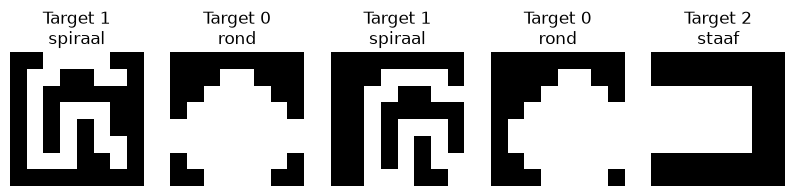

In [6]:
import matplotlib.pyplot as plt

# Wij gebruiken hierboven opgehaalde batch.

# Maak ruimte voor 5 afbeeldingen naast elkaar
fig, assen = plt.subplots(1, 5, figsize=(10, 2))

for i in range(5):

    # Afbeelding tonen
    assen[i].imshow(
        afbeeldingen[i][0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Numeriek targets ophalen
    target_klasse = targets[i].item()

    # Numerieke target_klasse omzetten naar de naam van de klasse
    klasse = train_dataset.classes[target_klasse]

    # Target en klasse boven de afbeelding zetten
    assen[i].set_title(f"Target {target_klasse}\n{klasse}")

    assen[i].axis("off")

plt.show()

## 4. De eerste convolutionele laag

Tot nu toe hebben we de invoer voorbereid:

- iedere afbeelding heeft de vorm `[1, 8, 8]`;
- `1` betekent één grijswaardenkanaal;
- iedere afbeelding heeft een target: `0`, `1` of `2`.

Nu bouwen we het eerste onderdeel van het CNN: een **convolutionele laag**.

Een convolutionele laag gebruikt kleine filters, ook wel kernels genoemd. Deze filters schuiven over de afbeelding en zoeken naar lokale patronen.

In dit experiment gebruiken we:

- 1 invoerkanaal;
- 2 filters;
- kernels van 3 × 3 pixels.

Ieder filter heeft eigen weights en maakt zijn eigen feature map.

De weights van deze filters worden tijdens het trainen geleerd.

In [7]:
import torch.nn as nn

conv = nn.Conv2d(
    in_channels=1,
    out_channels=2,
    kernel_size=3
)

print(conv)

Conv2d(1, 2, kernel_size=(3, 3), stride=(1, 1))


In [8]:
# Wij gebruiken hier de eerder opgehaalde batch welke hierboven gevisualiseerd staat.
# Stuur de afbeeldingen van de batch door de convolutionele laag
feature_maps = conv(afbeeldingen)

print("Invoer:", afbeeldingen.shape)
print("Uitvoer:", feature_maps.shape)
print("Targets:", targets)

Invoer: torch.Size([5, 1, 8, 8])
Uitvoer: torch.Size([5, 2, 6, 6])
Targets: tensor([1, 0, 1, 0, 2])


### Feature maps visualiseren

Onze convolutionele laag bevat twee filters van 3×3 pixels.

Ieder filter verwerkt dezelfde invoerafbeelding, maar gebruikt eigen weights. Daardoor ontstaan twee verschillende feature maps.

We bekijken:
- de oorspronkelijke afbeelding van 8×8 pixels;
- de feature map van filter 1 (6×6);
- de feature map van filter 2 (6×6).

De filters zijn nog niet getraind. Hun weights zijn willekeurig geïnitialiseerd.

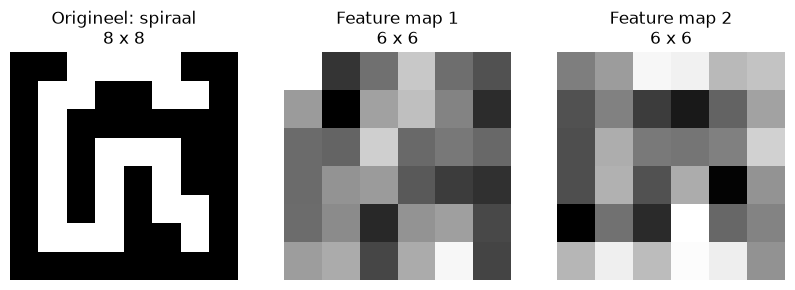

In [9]:
# We bekijken de eerste afbeelding uit onze bestaande batch
nummer = 0

# Juiste antwoord (target) ophalen
target_klasse = targets[nummer].item()
klasse = train_dataset.classes[target_klasse]

# Maak drie afbeeldingen ( 1 afbeelding en 2 feature maps) naast elkaar
fig, assen = plt.subplots(1, 3, figsize=(10, 3))

# Oorspronkelijke afbeelding
assen[0].imshow(
    afbeeldingen[nummer][0].detach(),
    cmap="gray",
    vmin=0,
    vmax=1
)
assen[0].set_title(f"Origineel: {klasse}\n8 x 8")

# Feature map van filter 1
assen[1].imshow(
    feature_maps[nummer][0].detach(),
    cmap="gray"
)
assen[1].set_title("Feature map 1\n6 x 6")

# Feature map van filter 2
assen[2].imshow(
    feature_maps[nummer][1].detach(),
    cmap="gray"
)
assen[2].set_title("Feature map 2\n6 x 6")

for as_ in assen:
    as_.axis("off")

plt.show()

### 5. Hoe berekent een kernel een feature map?

Een convolutionele laag gebruikt filters (kernels) om patronen in een afbeelding te onderzoeken.

Onze laag heeft twee kernels van 3×3. Iedere kernel bevat negen weights (gewichten) en één bias.

De kernel schuift over de afbeelding. Op iedere positie:
1. Vermenigvuldigt de kernel de negen pixelwaarden met de bijbehorende weights.
2. Telt de negen uitkomsten bij elkaar op.
3. Telt de bias erbij op.

Het resultaat is één waarde in de feature map.

In [10]:
# Bekijk de eerste kernel van onze convolutionele laag
kernel = conv.weight[0, 0].detach()
bias = conv.bias[0].detach()

print("Kernel 1:")
print(kernel)

print("\nBias:")
print(bias)

Kernel 1:
tensor([[-0.2393, -0.2969,  0.2438],
        [-0.2328, -0.2099,  0.2083],
        [-0.3318, -0.0452,  0.0074]])

Bias:
tensor(0.2324)


In [11]:
# Eerste afbeelding, eerste 3×3 pixels
pixels = afbeeldingen[0, 0, 0:3, 0:3]

print("Pixelwaarden:")
print(pixels)

# Vermenigvuldig pixels met de weights
producten = pixels * kernel

print("\nPixels × weights:")
print(producten)

# Tel alles op en voeg de bias toe
uitkomst = producten.sum() + bias

print("\nZelf berekende waarde:", uitkomst.item())

# Vergelijk met PyTorch
print("Waarde in feature map:", feature_maps[0, 0, 0, 0].item())

Pixelwaarden:
tensor([[0., 0., 1.],
        [0., 1., 1.],
        [0., 1., 0.]])

Pixels × weights:
tensor([[-0.0000, -0.0000,  0.2438],
        [-0.0000, -0.2099,  0.2083],
        [-0.0000, -0.0452,  0.0000]])

Zelf berekende waarde: 0.42935600876808167
Waarde in feature map: 0.42935600876808167


### Dense Layer (Fully Connected Layer)

Een Dense Layer gebruikt de kenmerken uit de convolutionele laag om een voorspelling te maken.

Voordat we een Dense Layer kunnen gebruiken zetten we de feature maps met ReLu, Max pooling en Flatten
om naar één reeks getallen per afbeelding.
Na Max Pooling hebben we twee feature maps van 3×3: 2 x 3 x 3 = 18

Onze Dense Layer krijgt 18 invoerwaarden en produceert 3 uitvoerwaarden, één voor iedere bacterieklasse.

In [12]:
# ReLU en Max Pooling toepassen
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2)

x = relu(feature_maps)
x = pool(x)

print("Na pooling:", x.shape)

# Flatten: van feature maps naar een reeks getallen
flatten = nn.Flatten()
x = flatten(x)

print("Na flatten:", x.shape)

# Dense Layer
dense = nn.Linear(in_features=18, out_features=3)

scores = dense(x)

print("Na dense:", scores.shape)
print("Scores eerste afbeelding:", scores[0])

Na pooling: torch.Size([5, 2, 3, 3])
Na flatten: torch.Size([5, 18])
Na dense: torch.Size([5, 3])
Scores eerste afbeelding: tensor([ 0.0975, -0.0369, -0.0912], grad_fn=<SelectBackward0>)


### Stap 6. Classificatie met de Dense Layer

De Dense Layer berekent voor iedere afbeelding drie scores.

Hoeveel weights heeft onze Dense Layer?

18 invoerwaarden x 3 uitvoerwaarden = 54 weights + 3 biases, één voor iedere uitvoerwaarde = 57 trainbare parameters.

Met `argmax()` bepalen we welke klasse de hoogste score heeft. Deze klasse is de voorspelling van het CNN.

Omdat het CNN nog niet getraind is, zijn de voorspellingen voorlopig willekeurig en niet betrouwbaar.

In [13]:
# Bekijk de scores van de eerste afbeelding
print("Scores:", scores[0].detach())

# Bepaal de klasse met de hoogste score
voorspelde_klasse = scores[0].argmax().item()

# Zet het klassenummer om naar een klassenaam
klasse_naam = train_dataset.classes[voorspelde_klasse]

# Vergelijk met het juiste antwoord
juiste_klasse = targets[0].item()
juiste_naam = train_dataset.classes[juiste_klasse]

print("Voorspelde klasse:", klasse_naam)
print("Juiste klasse:", juiste_naam)

Scores: tensor([ 0.0975, -0.0369, -0.0912])
Voorspelde klasse: rond
Juiste klasse: spiraal


### Stap 7. De fout berekenen met CrossEntropyLoss

Ons CNN heeft voor iedere afbeelding drie klassenscores berekend.

Met CrossEntropyLoss vergelijken we deze scores met de juiste
klasse (target).

Een lagere loss betekent dat het model volgens deze foutfunctie
betere voorspellingen doet.

CrossEntropyLoss gebruikt de ruwe scores van de Dense Layer.
We hoeven dus niet zelf Softmax toe te passen.

In [14]:
# Foutfunctie aanmaken
loss_functie = nn.CrossEntropyLoss()

# Bereken de gemiddelde loss van onze batch
loss = loss_functie(scores, targets)

print("Scores van de batch:")
print(scores.detach())

print("\nJuiste klassen:")
print(targets)

print("\nGemiddelde loss:", loss.item())

Scores van de batch:
tensor([[ 0.0975, -0.0369, -0.0912],
        [ 0.0093, -0.0378,  0.0471],
        [ 0.0789,  0.0225, -0.0893],
        [-0.0696,  0.0891,  0.1018],
        [ 0.0245,  0.0882,  0.0761]])

Juiste klassen:
tensor([1, 0, 1, 0, 2])

Gemiddelde loss: 1.120937705039978


### Stap 8. Backpropagation

Met backpropagation berekent PyTorch voor iedere trainbare
weight en bias een gradiënt.

Een gradiënt geeft aan in welke richting en hoe sterk de loss verandert wanneer een weight of bias een klein beetje verandert.

Met andere woorden geeft een gradiënt aan hoe gevoelig de loss is voor een
verandering van die parameter in een bepaalde richting.

Met `loss.backward()` worden de gradiënten berekend,
maar de weights en biases worden nog niet aangepast.

Dat doet later de optimizer.

In [15]:
# Bereken de gradiënten
loss.backward()

# Bekijk de gradiënten van de Dense Layer
print("Gradiënten van de Dense Layer:")
print(dense.weight.grad)

print("\nVorm:", dense.weight.grad.shape)

# Bekijk de gradiënten van de eerste convolutionele kernel
print("\nGradiënten van kernel 1:")
print(conv.weight.grad[0, 0])

Gradiënten van de Dense Layer:
tensor([[-0.0463, -0.0456,  0.0106, -0.0257,  0.0270,  0.0076, -0.0047,  0.0003,
          0.0287,  0.0000,  0.0209,  0.0085,  0.0000,  0.0000,  0.0000, -0.0011,
          0.0189,  0.0300],
        [-0.0635,  0.0081, -0.0196, -0.0543, -0.0497, -0.0141, -0.0648, -0.0006,
         -0.0524,  0.0000, -0.0385, -0.0157,  0.0000,  0.0000,  0.0000, -0.0012,
         -0.0180, -0.0279],
        [ 0.1099,  0.0376,  0.0090,  0.0801,  0.0226,  0.0065,  0.0695,  0.0003,
          0.0238,  0.0000,  0.0175,  0.0072,  0.0000,  0.0000,  0.0000,  0.0023,
         -0.0009, -0.0021]])

Vorm: torch.Size([3, 18])

Gradiënten van kernel 1:
tensor([[ 0.0548, -0.0017,  0.1107],
        [ 0.0318,  0.1348,  0.1242],
        [ 0.0479,  0.1457,  0.0785]])


### Stap 9. Weights aanpassen met de optimizer

Backpropagation heeft de gradiënten berekend, maar nog geen
weights of biases aangepast.

De optimizer gebruikt deze gradiënten om een stap te zetten
in de richting waarin de loss naar verwachting afneemt.

We gebruiken SGD met een learning rate van 0.01.

De optimizer past de parameters van zowel de convolutionele
laag als de Dense Layer aan.

We volgen hieronder slechts één weight om de werking inzichtelijk te maken.

In [16]:
import torch.optim as optim

# Maak de optimizer voor beide lagen
optimizer = optim.SGD(
    list(conv.parameters()) + list(dense.parameters()),
    lr=0.01
)

# Bewaar één weight vóór de aanpassing
weight_voor = dense.weight[0, 0].item()

# Bekijk de bijbehorende gradiënt
gradient = dense.weight.grad[0, 0].item()

# Bereken wat de nieuwe weight zou moeten zijn
verwachte_weight = weight_voor - 0.01 * gradient

# Pas alle weights en biases aan
optimizer.step()

# Bekijk dezelfde weight na de aanpassing
weight_na = dense.weight[0, 0].item()

print("Weight vóór:", weight_voor)
print("Gradiënt:", gradient)
print("Verwachte nieuwe weight:", verwachte_weight)
print("Weight na:", weight_na)

Weight vóór: -0.0016405284404754639
Gradiënt: -0.046344026923179626
Verwachte nieuwe weight: -0.0011770881712436676
Weight na: -0.0011770881246775389


### Stap 10. Het CNN trainen

Een epoch betekent dat het CNN alle trainingsafbeeldingen
één keer heeft verwerkt.

We hebben 30 trainingsafbeeldingen en een batchgrootte van 5.
Daarom bevat één epoch 6 batches.

Voor iedere batch:
1. Wissen we de oude gradiënten.
2. Berekenen we de voorspellingen (forward pass).
3. Berekenen we de loss.
4. Berekenen we de gradiënten (backpropagation).
5. Past de optimizer de weights en biases aan.

Na iedere epoch berekenen we de gemiddelde trainingsloss.

In [17]:
# Train het CNN gedurende één epoch
totale_loss = 0

for afbeeldingen, targets in train_loader:

    # 1. Oude gradiënten wissen
    optimizer.zero_grad()

    # 2. Forward pass
    x = conv(afbeeldingen)
    x = relu(x)
    x = pool(x)
    x = flatten(x)
    scores = dense(x)

    # 3. Loss berekenen
    loss = loss_functie(scores, targets)

    # 4. Backpropagation
    loss.backward()

    # 5. Weights en biases aanpassen
    optimizer.step()

    # Loss van deze batch optellen
    totale_loss += loss.item()

# Gemiddelde loss van alle batches
gemiddelde_loss = totale_loss / len(train_loader)

print("Aantal batches:", len(train_loader))
print("Gemiddelde trainingsloss:", gemiddelde_loss)

Aantal batches: 6
Gemiddelde trainingsloss: 1.0962757070859273


### Stap 11. Trainen met meerdere epochs

Tijdens één epoch verwerkt het CNN alle 30 trainingsafbeeldingen.

We trainen nu gedurende 20 epochs. Na iedere epoch berekenen
we de gemiddelde trainingsloss en bewaren we deze waarde.

Met een grafiek onderzoeken we of de loss tijdens de training
afneemt. Een dalende loss betekent dat het CNN de
trainingsgegevens steeds beter leert voorspellen.

In [18]:
aantal_epochs = 20
training_losses = []

for epoch in range(aantal_epochs):

    totale_loss = 0

    for afbeeldingen, targets in train_loader:

        # 1. Oude gradiënten wissen
        optimizer.zero_grad()

        # 2. Forward pass
        x = conv(afbeeldingen)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        # 3. Loss berekenen
        loss = loss_functie(scores, targets)

        # 4. Backpropagation
        loss.backward()

        # 5. Weights aanpassen
        optimizer.step()

        # Loss van de batch verzamelen
        totale_loss += loss.item()

    # Gemiddelde loss van deze epoch
    gemiddelde_loss = totale_loss / len(train_loader)
    training_losses.append(gemiddelde_loss)

    print(f"Epoch {epoch + 1}: loss = {gemiddelde_loss:.4f}")

Epoch 1: loss = 1.0945
Epoch 2: loss = 1.0933
Epoch 3: loss = 1.0915
Epoch 4: loss = 1.0898
Epoch 5: loss = 1.0864
Epoch 6: loss = 1.0840
Epoch 7: loss = 1.0813
Epoch 8: loss = 1.0794
Epoch 9: loss = 1.0766
Epoch 10: loss = 1.0730
Epoch 11: loss = 1.0684
Epoch 12: loss = 1.0655
Epoch 13: loss = 1.0612
Epoch 14: loss = 1.0568
Epoch 15: loss = 1.0531
Epoch 16: loss = 1.0491
Epoch 17: loss = 1.0458
Epoch 18: loss = 1.0425
Epoch 19: loss = 1.0386
Epoch 20: loss = 1.0334


### Stap 12 – Validatie van het CNN

Na het trainen onderzoeken we hoe goed het CNN presteert
op afbeeldingen die niet tijdens de training zijn gebruikt.

We gebruiken hiervoor de validatiedataset met 9 afbeeldingen.

We berekenen:
- Validation loss: de gemiddelde foutwaarde.
- Accuracy: het percentage correct geclassificeerde afbeeldingen.

Tijdens validatie passen we de weights en biases niet aan.

In [20]:
# Validatie van ons CNN
import torch
totale_loss = 0
aantal_correct = 0
aantal_afbeeldingen = 0

# Tijdens validatie berekenen we geen gradiënten
with torch.no_grad():

    for afbeeldingen, targets in validation_loader:

        # Forward pass
        x = conv(afbeeldingen)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        # Validation loss
        loss = loss_functie(scores, targets)
        totale_loss += loss.item() * len(targets)

        # Voorspelde klassen bepalen
        voorspellingen = scores.argmax(dim=1)

        # Vergelijk voorspellingen met de juiste targets
        aantal_correct += (voorspellingen == targets).sum().item()
        aantal_afbeeldingen += len(targets)

# Resultaten
validation_loss = totale_loss / aantal_afbeeldingen
accuracy = aantal_correct / aantal_afbeeldingen * 100

print(f"Validation loss: {validation_loss:.4f}")
print(f"Correct: {aantal_correct} van {aantal_afbeeldingen}")
print(f"Accuracy: {accuracy:.1f}%")

Validation loss: 1.0028
Correct: 4 van 9
Accuracy: 44.4%



## Stap 13 – Voorspellingen van het CNN analyseren

### Doel
We onderzoeken welke bacterievormen het CNN correct en onjuist classificeert.

### Waarom is deze analyse belangrijk?
Een accuracy van 44,4% vertelt ons hoeveel afbeeldingen correct zijn geclassificeerd maar niet **waarom** het model fouten maakt.

Door de voorspellingen per afbeelding te bekijken kunne we onderzoeken:

- Welke bacterievormen het CNN goed herkent.
- Welke bacterievormen het CNN met elkaar verwart.
- Of het CNN misschien steeds dezelfde klasse voorspelt.

### Werkwijze
We gebruiken de 9 afbeeldingen uit de validatiedataset.

Voor iedere afbeelding vergelijken we:
1. De werkelijke klasse (*target*).
2. De voorspelde klasse (*prediction*).
3. Of de voorspelling correct of fout is.

Tijdens deze analyse trainen we het CNN niet verder. De weights en biases blijven ongewijzigd.


In [21]:

# Voorspellingen van de validatiedataset verzamelen

alle_voorspellingen = []
alle_targets = []

with torch.no_grad():

    for afbeeldingen, targets in validation_loader:

        # Forward pass
        x = conv(afbeeldingen)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        # Klasse met de hoogste score kiezen
        voorspellingen = scores.argmax(dim=1)

        # Voorspellingen en targets bewaren
        alle_voorspellingen.extend(voorspellingen.tolist())
        alle_targets.extend(targets.tolist())

print("Voorspellingen:", alle_voorspellingen)
print("Targets:", alle_targets)


Voorspellingen: [1, 1, 1, 1, 1, 1, 1, 1, 2]
Targets: [0, 0, 0, 1, 1, 1, 2, 2, 2]



### Klassenummers omzetten naar bacterievormen

Het CNN werkt met numerieke klassen:

- `0` = rond
- `1` = spiraal
- `2` = staaf

Deze indeling is automatisch bepaald door `ImageFolder`, op basis van de alfabetische volgorde van de mapnamen.

Voor mensen zijn klassennamen duidelijker dan getallen. Daarom zetten we de targets en voorspellingen om naar de bijbehorende bacterievormen.

Vervolgens vergelijken we beide waarden per afbeelding.


In [22]:

# Werkelijke en voorspelde klassen vergelijken

klassen = validation_dataset.classes

aantal_correct = 0

print(f"{'Afbeelding':<12} {'Werkelijk':<12} {'Voorspeld':<12} Resultaat")
print("-" * 50)

for i in range(len(alle_targets)):

    werkelijk = klassen[alle_targets[i]]
    voorspeld = klassen[alle_voorspellingen[i]]

    if werkelijk == voorspeld:
        resultaat = "Correct"
        aantal_correct += 1
    else:
        resultaat = "Fout"

    print(f"{i + 1:<12} {werkelijk:<12} {voorspeld:<12} {resultaat}")

print()
print(f"Totaal correct: {aantal_correct} van {len(alle_targets)}")


Afbeelding   Werkelijk    Voorspeld    Resultaat
--------------------------------------------------
1            rond         spiraal      Fout
2            rond         spiraal      Fout
3            rond         spiraal      Fout
4            spiraal      spiraal      Correct
5            spiraal      spiraal      Correct
6            spiraal      spiraal      Correct
7            staaf        spiraal      Fout
8            staaf        spiraal      Fout
9            staaf        staaf        Correct

Totaal correct: 4 van 9



### Stap 14. Reflectie op de resultaten

Na 20 epochs hebben we ons CNN getest met 9 validatieafbeeldingen.

**Resultaten:**
- Correct geclassificeerd: 4 van de 9 afbeeldingen.
- Accuracy: 44,4%.
- Validation loss: 1,0028.

### Onderzoeksvragen en antwoorden

**1. Welke bacterievorm wordt het vaakst correct herkend?**

De bacterievorm **spiraal** wordt het beste herkend.

- Rond: 0 van de 3 correct (0%).
- Spiraal: 3 van de 3 correct (100%).
- Staaf: 1 van de 3 correct (33,3%).

**2. Welke bacterievormen worden met elkaar verward?**

Het CNN verwart vooral andere bacterievormen met spiraal.

- Alle 3 de ronde bacteriën worden als spiraal geclassificeerd.
- Van de 3 staafvormige bacteriën worden er 2 als spiraal geclassificeerd.
- Alle spiraalvormige bacteriën worden correct herkend.

**3. Voorspelt het CNN alle drie de klassen, of heeft het een voorkeur voor één klasse?**

Het CNN heeft een duidelijke voorkeur voor de klasse **spiraal**.

Van de 9 afbeeldingen voorspelt het CNN:
- Rond: 0 keer.
- Spiraal: 8 keer.
- Staaf: 1 keer.

Het CNN voorspelt dus niet alle drie de klassen. De klasse rond wordt helemaal niet voorspeld.

**4. Wat zegt dit over de kwaliteit van ons model?**

De trainingsloss is tijdens de 20 epochs gedaald van 1,0945 naar 1,0334. Dit laat zien dat het CNN tijdens de training vooruitgang boekt.

De accuracy op de validatiedataset is echter slechts 44,4%.

Het CNN herkent de spiraalvormige bacteriën goed, maar heeft moeite met ronde en staafvormige bacteriën.

Het model heeft dus nog niet geleerd om alle drie de bacterievormen betrouwbaar van elkaar te onderscheiden.

### Voorlopige conclusie

Ons CNN leert, maar de classificatie is nog onvoldoende betrouwbaar.

Het model heeft een sterke voorkeur voor de klasse spiraal. Hierdoor worden veel afbeeldingen verkeerd geclassificeerd.

Mogelijke verklaringen zijn:
- Het CNN heeft nog onvoldoende training gehad.
- De learning rate is mogelijk te laag.
- De convolutionele filters hebben nog onvoldoende onderscheidende kenmerken geleerd.

Op basis van slechts 9 validatieafbeeldingen kunnen we nog geen definitieve conclusies trekken.

**Vervolgstap:** We gaan de validatieafbeeldingen met hun voorspelde en werkelijke klassen visualiseren. Daarna onderzoeken we hoe we het CNN kunnen verbeteren.



## Stap 15. Voorspellingen visualiseren

### Doel

We gaan de 9 validatieafbeeldingen tonen en vergelijken
de werkelijke bacterievorm met de voorspelling van het CNN.

### Waarom visualiseren?

Bij stap 18 ontdekten we dat het CNN:

- 0 van de 3 ronde bacteriën correct herkent.
- 3 van de 3 spiraalvormige bacteriën correct herkent.
- 1 van de 3 staafvormige bacteriën correct herkent.

Het CNN voorspelt 8 van de 9 afbeeldingen als spiraal.

Door de afbeeldingen te bekijken, onderzoeken we of
er zichtbare kenmerken zijn die de fouten kunnen verklaren.

### Werkwijze

We tonen de 9 validatieafbeeldingen in een raster van 3 × 3.

Bij iedere afbeelding vermelden we:
- De werkelijke klasse (target).
- De voorspelde klasse.
- Of de voorspelling correct of fout is.

We passen de weights en biases niet aan.


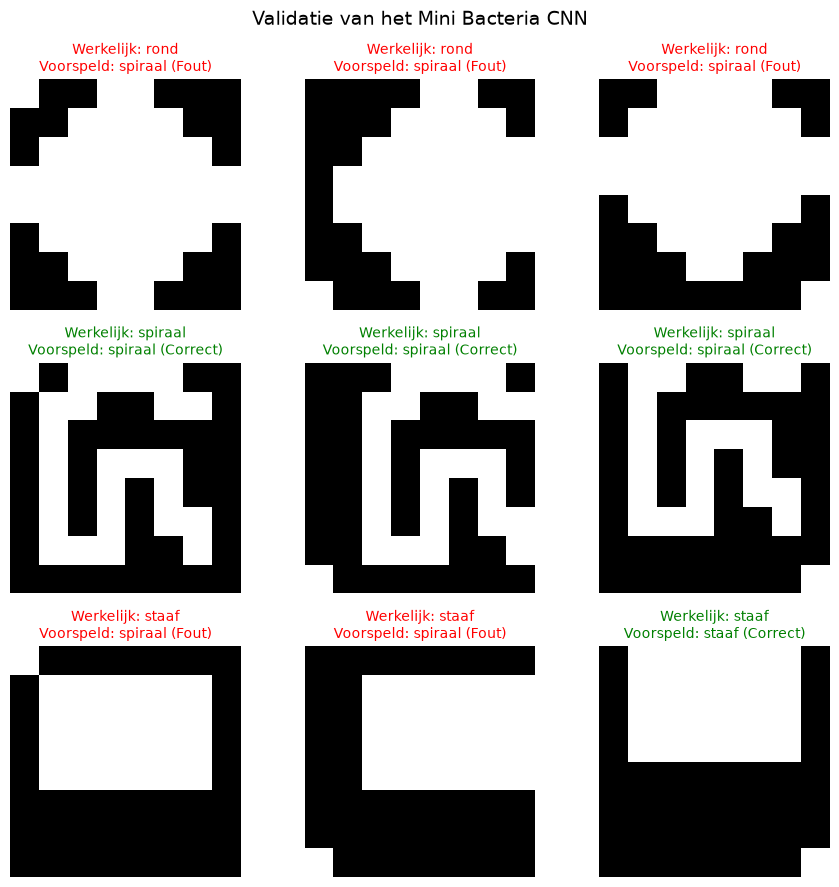

In [23]:

# Validatieafbeeldingen visualiseren

import matplotlib.pyplot as plt

fig, assen = plt.subplots(3, 3, figsize=(9, 9))

klassen = validation_dataset.classes

for i in range(len(validation_dataset)):

    # Afbeelding ophalen
    afbeelding, target_klasse = validation_dataset[i]

    # Voorspelling uit stap 18
    voorspelde_klasse = alle_voorspellingen[i]

    # Klassenummers omzetten naar namen
    werkelijk = klassen[target_klasse]
    voorspeld = klassen[voorspelde_klasse]

    # Controleren of de voorspelling correct is
    correct = target_klasse == voorspelde_klasse

    if correct:
        resultaat = "Correct"
        kleur = "green"
    else:
        resultaat = "Fout"
        kleur = "red"

    # Positie in het raster
    ax = assen.flat[i]

    # Afbeelding tonen
    ax.imshow(afbeelding.squeeze(), cmap="gray",
              vmin=0, vmax=1, interpolation="nearest")

    ax.set_title(
        f"Werkelijk: {werkelijk}\n"
        f"Voorspeld: {voorspeld} ({resultaat})",
        color=kleur,
        fontsize=10
    )

    ax.axis("off")

plt.suptitle("Validatie van het Mini Bacteria CNN", fontsize=14)
plt.tight_layout()
plt.show()



## Stap 16. Klassenscores en kansen analyseren

### Doel

We onderzoeken hoe het CNN tot een voorspelling komt.

De Dense Layer geeft voor iedere afbeelding drie scores:
- Score voor rond.
- Score voor spiraal.
- Score voor staaf.

De klasse met de hoogste score wordt de voorspelling.

### Van scores naar kansen

De uitvoer van de Dense Layer bestaat uit ruwe scores.
Dit zijn nog geen kansen.

Met de functie softmax zetten we deze scores om naar
waarden tussen 0 en 1, waarvan de som gelijk is aan 1.

Bijvoorbeeld:
- Rond: 0,30 (30%)
- Spiraal: 0,45 (45%)
- Staaf: 0,25 (25%)

Het CNN voorspelt dan spiraal, omdat deze klasse de
hoogste waarde heeft.

Let op: een softmaxwaarde van 45% betekent niet automatisch
dat de voorspelling in werkelijkheid met 45% zekerheid
correct is. Het zijn door het model berekende kansen.


In [24]:

# Scores van één validatieafbeelding

# Eerste afbeelding ophalen
afbeelding, target_klasse = validation_dataset[0]

# Een batchdimensie toevoegen: [1, 8, 8] -> [1, 1, 8, 8]
afbeelding = afbeelding.unsqueeze(0)

with torch.no_grad():

    # Forward pass
    x = conv(afbeelding)
    x = relu(x)
    x = pool(x)
    x = flatten(x)
    scores = dense(x)

    # Scores omzetten naar kansen
    kansen = torch.softmax(scores, dim=1)

# Resultaten tonen
print("Werkelijke klasse:", validation_dataset.classes[target_klasse])
print()

for i, klassenaam in enumerate(validation_dataset.classes):
    print(f"{klassenaam}: score = {scores[0, i].item():.4f}, "
          f"kans = {kansen[0, i].item() * 100:.1f}%")

voorspelde_klasse = scores.argmax(dim=1).item()

print()
print("Voorspelde klasse:",
      validation_dataset.classes[voorspelde_klasse])


Werkelijke klasse: rond

rond: score = 0.0709, kans = 34.2%
spiraal: score = 0.1150, kans = 35.7%
staaf: score = -0.0580, kans = 30.1%

Voorspelde klasse: spiraal



### Stap 17. Reflectie op de klassenscores

We hebben de eerste validatieafbeelding onderzocht.

**Werkelijke klasse:** rond  
**Voorspelde klasse:** spiraal

| Klasse | Score | Kans |
|---|---:|---:|
| Rond | 0,0709 | 34,2% |
| Spiraal | 0,1150 | 35,7% |
| Staaf | -0,0580 | 30,1% |

#### Onderzoeksvragen en antwoorden

**1. Welke klasse heeft de hoogste score?**

De klasse spiraal heeft de hoogste score (0,1150) en
de hoogste softmaxwaarde (35,7%).

Daarom voorspelt het CNN spiraal.

**2. Hoe groot is het verschil tussen de kansen voor rond en spiraal?**

- Rond: 34,2%
- Spiraal: 35,7%

Het verschil is slechts 1,5 procentpunt.

**3. Is de voorspelling duidelijk, of liggen de kansen dicht bij elkaar?**

De kansen liggen dicht bij elkaar.

Bij drie klassen zou een gelijke kansverdeling bestaan
uit ongeveer 33,3% per klasse.

Onze resultaten liggen daar dicht bij. Het CNN maakt
bij deze afbeelding dus nog weinig onderscheid tussen
de drie bacterievormen.

**4. Wat kunnen we hieruit afleiden over de huidige prestaties van ons CNN?**

Het CNN voorspelt de verkeerde klasse, maar het verschil
tussen rond en spiraal is erg klein.

De resultaten suggereren dat het model nog onvoldoende
onderscheidende kenmerken heeft geleerd om deze afbeelding
betrouwbaar te classificeren.

Dit past bij de eerdere resultaten:
- De trainingsloss daalt langzaam.
- De validation accuracy is 44,4%.
- Het CNN voorspelt 8 van de 9 afbeeldingen als spiraal.

### Conclusie

Het CNN heeft geleerd om de trainingsloss te verlagen,
maar onderscheidt de bacterievormen nog onvoldoende.

De voorspelling spiraal wordt veroorzaakt door een
klein verschil in de klassenscores.

Een voorspelling is dus niet automatisch betrouwbaar
omdat één klasse de hoogste score heeft.

### Vervolg

Bij stap 21 onderzoeken we de klassenscores van alle
9 validatieafbeeldingen. Zo kunnen we vaststellen of
het CNN ook bij andere afbeeldingen zulke kleine
verschillen tussen de klassen laat zien.



## Stap 18. Kansverdelingen van alle validatieafbeeldingen

### Doel

We onderzoeken hoe het CNN de drie bacterievormen beoordeelt
bij alle 9 validatieafbeeldingen.

Bij stap 20 hebben we één afbeelding onderzocht.
Nu breiden we dit uit naar de volledige validatiedataset.

### Onderzoeksvragen

1. Heeft spiraal bij bijna alle afbeeldingen de hoogste kans?
2. Zijn de verschillen tussen de drie kansen groot of klein?
3. Zijn de kansen bij correcte voorspellingen duidelijker verdeeld
   dan bij foutieve voorspellingen?
4. Wat vertellen de resultaten over het leerproces van ons CNN?

### Werkwijze

Voor iedere afbeelding:
1. Voeren we een forward pass uit.
2. Berekenen we de drie klassenscores.
3. Zetten we de scores met softmax om naar kansen.
4. Bepalen we de voorspelde klasse.
5. Vergelijken we deze met de werkelijke klasse.

We trainen het CNN niet verder.
De weights en biases blijven ongewijzigd.


In [25]:

# Kansverdelingen van alle validatieafbeeldingen

alle_kansen = []

with torch.no_grad():

    for afbeelding, target_klasse in validation_dataset:

        # Batchdimensie toevoegen
        afbeelding = afbeelding.unsqueeze(0)

        # Forward pass
        x = conv(afbeelding)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        # Scores omzetten naar kansen
        kansen = torch.softmax(scores, dim=1)

        # Drie kansen bewaren als Python-lijst
        alle_kansen.append(kansen[0].tolist())

print("Aantal afbeeldingen:", len(alle_kansen))
print("Kansen eerste afbeelding:", alle_kansen[0])


Aantal afbeeldingen: 9
Kansen eerste afbeelding: [0.34196561574935913, 0.35740944743156433, 0.30062490701675415]


In [26]:

# Kansverdelingen in een tabel tonen

klassen = validation_dataset.classes

print(
    f"{'Nr.':<5} {'Werkelijk':<10} "
    f"{'Rond':>8} {'Spiraal':>9} {'Staaf':>8} "
    f"{'Voorspeld':>12} {'Resultaat':>10}"
)

print("-" * 75)

for i in range(len(validation_dataset)):

    # Werkelijke klasse ophalen
    afbeelding, target_klasse = validation_dataset[i]
    werkelijk = klassen[target_klasse]

    # Kansen uit stap 21.2
    kansen = alle_kansen[i]

    # Klasse met hoogste kans
    voorspelde_klasse = kansen.index(max(kansen))
    voorspeld = klassen[voorspelde_klasse]

    # Correct of fout
    resultaat = "Correct" if voorspelde_klasse == target_klasse else "Fout"

    print(
        f"{i + 1:<5} {werkelijk:<10} "
        f"{kansen[0] * 100:>7.1f}% "
        f"{kansen[1] * 100:>8.1f}% "
        f"{kansen[2] * 100:>7.1f}% "
        f"{voorspeld:>12} {resultaat:>10}"
    )


Nr.   Werkelijk      Rond   Spiraal    Staaf    Voorspeld  Resultaat
---------------------------------------------------------------------------
1     rond          34.2%     35.7%    30.1%      spiraal       Fout
2     rond          33.5%     34.4%    32.1%      spiraal       Fout
3     rond          33.6%     36.5%    29.9%      spiraal       Fout
4     spiraal       29.9%     42.3%    27.8%      spiraal    Correct
5     spiraal       31.9%     43.3%    24.8%      spiraal    Correct
6     spiraal       27.8%     41.7%    30.5%      spiraal    Correct
7     staaf         30.1%     35.4%    34.4%      spiraal       Fout
8     staaf         29.8%     36.2%    34.0%      spiraal       Fout
9     staaf         30.2%     34.9%    35.0%        staaf    Correct


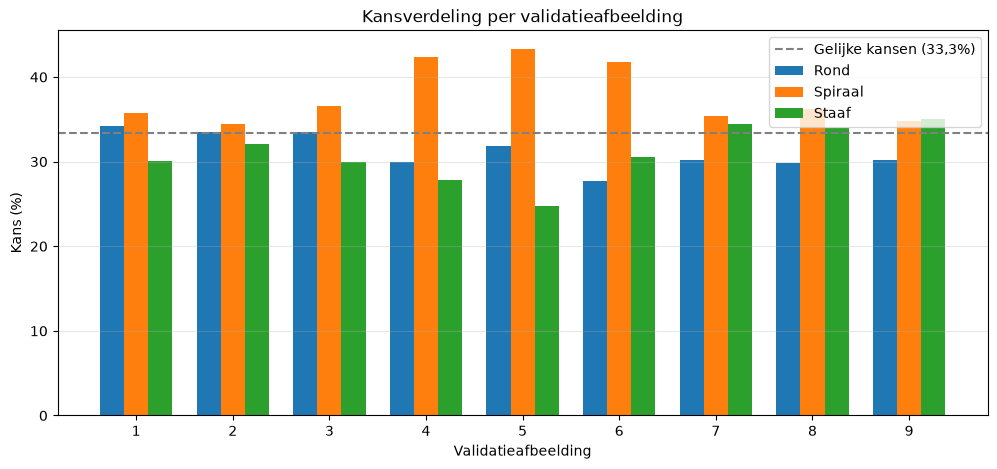

In [27]:

# Kansverdelingen visualiseren

import numpy as np

kansen_array = np.array(alle_kansen) * 100

posities = np.arange(len(validation_dataset))
breedte = 0.25

plt.figure(figsize=(12, 5))

plt.bar(posities - breedte, kansen_array[:, 0],
        width=breedte, label="Rond")

plt.bar(posities, kansen_array[:, 1],
        width=breedte, label="Spiraal")

plt.bar(posities + breedte, kansen_array[:, 2],
        width=breedte, label="Staaf")

plt.axhline(100 / 3, linestyle="--",
            color="gray", label="Gelijke kansen (33,3%)")

plt.xticks(posities, range(1, 10))
plt.xlabel("Validatieafbeelding")
plt.ylabel("Kans (%)")
plt.title("Kansverdeling per validatieafbeelding")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()



### Stap 19 Reflectie op de kansverdelingen

We hebben de kansverdelingen van alle 9 validatieafbeeldingen
onderzocht met softmax.

De afbeeldingen zijn als volgt verdeeld:

- Afbeelding 1 t/m 3: rond.
- Afbeelding 4 t/m 6: spiraal.
- Afbeelding 7 t/m 9: staaf.

#### Onderzoeksvragen en antwoorden

**1. Heeft spiraal bij bijna alle afbeeldingen de hoogste kans?**

Ja. Bij 8 van de 9 afbeeldingen heeft spiraal de hoogste kans.

Alleen bij afbeelding 9 heeft staaf de hoogste kans.

Het CNN heeft dus een duidelijke voorkeur voor spiraal,
ongeacht de werkelijke bacterievorm.

**2. Zijn de verschillen tussen de drie kansen groot of klein?**

Dat verschilt per afbeelding.

- Bij de ronde bacteriën (1 t/m 3) liggen de kansen
  dicht bij elkaar. Rond en spiraal verschillen slechts
  enkele procentpunten.
- Bij de spiraalvormige bacteriën (4 t/m 6) zijn de
  verschillen groter. Spiraal krijgt ongeveer 42–43%.
- Bij de staafvormige bacteriën (7 t/m 9) liggen de
  kansen weer dichter bij elkaar.

Het CNN maakt dus bij de spiraalvormige bacteriën
meer onderscheid tussen de klassen dan bij de andere vormen.

**3. Zijn de kansen bij correcte voorspellingen duidelijker verdeeld dan bij foutieve voorspellingen?**

Niet altijd.

Bij de correct voorspelde spiraalvormige bacteriën
(4 t/m 6) is het verschil tussen de hoogste kans
en de andere kansen relatief groot.

Bij de correct voorspelde staafvormige bacterie
(afbeelding 9) liggen de kansen juist dicht bij elkaar.

Een correcte voorspelling betekent dus niet automatisch
dat het model een duidelijk onderscheid maakt.

**4. Wat vertellen de resultaten over het leerproces van ons CNN?**

Het CNN lijkt al enig onderscheid te hebben geleerd
voor spiraalvormige bacteriën.

Bij ronde en staafvormige bacteriën maakt het model
nog onvoldoende onderscheid.

Dit past bij onze eerdere resultaten:

- De trainingsloss is gedaald.
- De validation accuracy is 44,4%.
- Het CNN voorspelt bijna alles als spiraal.
- Veel softmaxwaarden liggen dicht bij 33,3%.

### Conclusie

Het CNN heeft nog onvoldoende geleerd om alle drie
de bacterievormen betrouwbaar te classificeren.

Vooral de spiraalvormige bacteriën krijgen duidelijk
hogere scores voor hun juiste klasse.

Bij de andere bacterievormen zijn de verschillen klein
en kiest het CNN vaak ten onrechte voor spiraal.

De softmaxwaarden geven inzicht in de voorkeuren van
het model, maar zijn geen garantie voor betrouwbare
voorspellingen.

### Vervolg

Bij stap 22 gaan we het CNN verder trainen.

Daarbij onderzoeken we:
1. Of de trainingsloss verder daalt.
2. Of de validation loss verandert.
3. Of de accuracy verbetert.
4. Of het CNN minder vaak dezelfde klasse voorspelt.



## Hyperparameters en trainbare parameters

Bij het ontwikkelen van een CNN maken we onderscheid tussen
parameters en hyperparameters.

### Trainbare parameters

Dit zijn de weights en biases van het neurale netwerk.

PyTorch initialiseert deze waarden en past ze tijdens
de training aan met behulp van backpropagation en
een optimizer.

Ons huidige CNN heeft 77 trainbare parameters.

### Hyperparameters

Dit zijn instellingen die de ontwikkelaar zelf kiest.

Voorbeelden:
- Learning rate: hoe groot de weight-updates zijn.
- Epochs: hoe vaak de volledige trainingsdataset wordt verwerkt.
- Batch size: hoeveel afbeeldingen per trainingsstap worden gebruikt.
- Aantal filters: hoeveel verschillende kenmerken een laag kan leren.
- Kernel size: hoeveel pixels een filter tegelijk bekijkt.
- Optimizer: welk algoritme de parameters aanpast.

### Modelontwikkeling

We kiezen een architectuur en hyperparameters, trainen het
CNN en beoordelen de resultaten met een validatiedataset.

Daarna kunnen we de instellingen aanpassen en opnieuw trainen.

Bij voorkeur veranderen we één hyperparameter tegelijk,
zodat we kunnen onderzoeken welk effect deze verandering heeft.

De testdataset bewaren we voor de uiteindelijke beoordeling
van het gekozen model.



## Stap 20. Verder trainen en valideren

We trainen het bestaande CNN nog 50 epochs verder.

Na iedere epoch meten we:
- Trainingsloss: hoe goed leert het CNN van de trainingsafbeeldingen?
- Validation loss: hoe goed presteert het CNN op nieuwe afbeeldingen?
- Validation accuracy: hoeveel validatieafbeeldingen worden correct herkend?

Zo onderzoeken we of langer trainen daadwerkelijk verbetering oplevert.

We gebruiken dezelfde architectuur, optimizer en learning rate.


In [28]:

# Nog 50 epochs trainen

aantal_epochs = 50

training_losses_22 = []
validation_losses_22 = []
validation_accuracies_22 = []

for epoch in range(aantal_epochs):

    # TRAINING
    totale_train_loss = 0

    for afbeeldingen, targets in train_loader:

        optimizer.zero_grad()

        x = conv(afbeeldingen)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        loss = loss_functie(scores, targets)
        loss.backward()
        optimizer.step()

        totale_train_loss += loss.item() * len(targets)

    train_loss = totale_train_loss / len(train_dataset)

    # VALIDATIE
    totale_val_loss = 0
    aantal_correct = 0

    with torch.no_grad():

        for afbeeldingen, targets in validation_loader:

            x = conv(afbeeldingen)
            x = relu(x)
            x = pool(x)
            x = flatten(x)
            scores = dense(x)

            loss = loss_functie(scores, targets)

            totale_val_loss += loss.item() * len(targets)

            voorspellingen = scores.argmax(dim=1)
            aantal_correct += (voorspellingen == targets).sum().item()

    val_loss = totale_val_loss / len(validation_dataset)
    val_accuracy = aantal_correct / len(validation_dataset) * 100

    # Resultaten bewaren
    training_losses_22.append(train_loss)
    validation_losses_22.append(val_loss)
    validation_accuracies_22.append(val_accuracy)

    # Iedere 10 epochs resultaten tonen
    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train loss = {train_loss:.4f}, "
            f"Val loss = {val_loss:.4f}, "
            f"Accuracy = {val_accuracy:.1f}%"
        )


Epoch 10: Train loss = 0.9858, Val loss = 0.9396, Accuracy = 66.7%
Epoch 20: Train loss = 0.9255, Val loss = 0.8699, Accuracy = 77.8%
Epoch 30: Train loss = 0.8650, Val loss = 0.8013, Accuracy = 100.0%
Epoch 40: Train loss = 0.8007, Val loss = 0.7271, Accuracy = 100.0%
Epoch 50: Train loss = 0.7364, Val loss = 0.6584, Accuracy = 100.0%


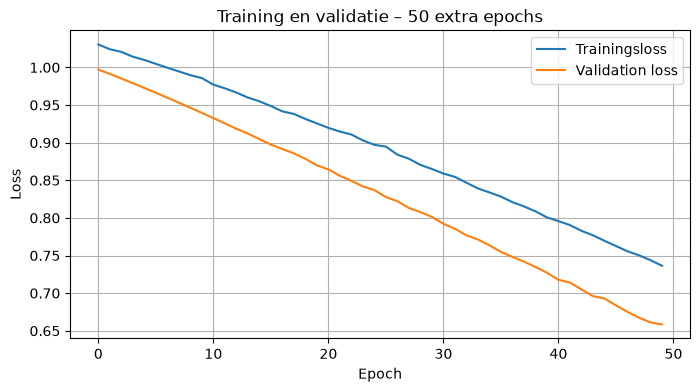

Laatste validation accuracy: 100.0%


In [29]:

# Trainingsloss en validation loss vergelijken

plt.figure(figsize=(8, 4))

plt.plot(training_losses_22, label="Trainingsloss")
plt.plot(validation_losses_22, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training en validatie – 50 extra epochs")
plt.legend()
plt.grid(True)

plt.show()

print(f"Laatste validation accuracy: {validation_accuracies_22[-1]:.1f}%")


In [30]:
print(f"Accuracy vóór extra training: 44.4%")
print(f"Accuracy na extra training: {validation_accuracies_22[-1]:.1f}%")
print(f"Correct geclassificeerd: {round(validation_accuracies_22[-1] / 100 * 9)} van 9")

Accuracy vóór extra training: 44.4%
Accuracy na extra training: 100.0%
Correct geclassificeerd: 9 van 9




### Definitieve conclusie - Extra training

Na 50 extra epochs is de validation accuracy gestegen
van 44,4% naar 100%.

Het CNN classificeert nu alle 9 validatieafbeeldingen correct.

Daarnaast zijn zowel de trainingsloss als de validation loss
verder gedaald.

Dit laat zien dat het CNN de kenmerken van de drie
bacterievormen beter heeft leren onderscheiden.

Op basis van de lossgrafiek zijn er geen duidelijke
aanwijzingen voor overfitting.

We kunnen echter nog niet concluderen dat het model
ook op volledig ongebruikte afbeeldingen goed presteert.

Daarom voeren we een eindtest uit met de aparte testdataset.




## Stap 21. Eindtest van het CNN

### Doel

We beoordelen het getrainde CNN met de testdataset.

De testdataset bevat 9 afbeeldingen:
- 3 ronde bacteriën.
- 3 spiraalvormige bacteriën.
- 3 staafvormige bacteriën.

### Verschil tussen validatie en test

**Training:** hiermee leert het CNN.

**Validatie:** hiermee beoordelen we tussentijds het model
en bepalen we of verdere training of aanpassing nodig is.

**Test:** hiermee beoordelen we het gekozen model op
afbeeldingen die niet voor training of modelkeuzes zijn gebruikt.

Tijdens de test veranderen we geen weights of biases.


In [31]:

# Eindtest

aantal_correct = 0
aantal_afbeeldingen = 0
totale_test_loss = 0

with torch.no_grad():

    for afbeeldingen, targets in test_loader:

        # Forward pass
        x = conv(afbeeldingen)
        x = relu(x)
        x = pool(x)
        x = flatten(x)
        scores = dense(x)

        # Loss berekenen
        loss = loss_functie(scores, targets)
        totale_test_loss += loss.item() * len(targets)

        # Voorspellingen controleren
        voorspellingen = scores.argmax(dim=1)

        aantal_correct += (voorspellingen == targets).sum().item()
        aantal_afbeeldingen += len(targets)

test_loss = totale_test_loss / aantal_afbeeldingen
test_accuracy = aantal_correct / aantal_afbeeldingen * 100

print(f"Test loss: {test_loss:.4f}")
print(f"Correct: {aantal_correct} van {aantal_afbeeldingen}")
print(f"Test accuracy: {test_accuracy:.1f}%")


Test loss: 0.8262
Correct: 7 van 9
Test accuracy: 77.8%



### Eindreflectie

#### Resultaten

| Meting | Resultaat |
|---|---|
| Validation accuracy | 100% (9 van 9) |
| Test accuracy | 77,8% (7 van 9) |
| Test loss | 0,8262 |

#### Onderzoeksvragen en antwoorden

**1. Hoeveel testafbeeldingen classificeert het CNN correct?**

Het CNN classificeert 7 van de 9 testafbeeldingen correct.

Twee afbeeldingen worden verkeerd geclassificeerd.

**2. Is de test accuracy vergelijkbaar met de validation accuracy?**

De test accuracy (77,8%) is lager dan de validation
accuracy (100%).

Dit verschil laat zien dat goede prestaties op de
validatiedataset niet automatisch dezelfde prestaties
op de testdataset betekenen.

**3. Wat kunnen we concluderen over het herkennen van nieuwe afbeeldingen?**

Het CNN heeft geleerd om onderscheid te maken tussen
de drie bacterievormen.

Het model herkent ook een groot deel van de afbeeldingen
die niet voor training of validatie zijn gebruikt.

De classificatie is echter niet foutloos.

#### Beperkingen van het experiment

- De trainingsdataset bevat slechts 30 afbeeldingen.
- De validatiedataset bevat 9 afbeeldingen.
- De testdataset bevat 9 afbeeldingen.
- De afbeeldingen zijn kunstmatig gegenereerd.
- De resolutie is slechts 8 × 8 pixels.

Door de kleine dataset is de accuracy gevoelig voor
individuele fouten. Eén fout komt overeen met ongeveer
11,1 procentpunt.

We kunnen daarom geen sterke conclusies trekken over
de prestaties op andere datasets.

### Eindconclusie

We hebben met PyTorch een eenvoudig Convolutional Neural
Network gebouwd, getraind, gevalideerd en getest.

Tijdens het project hebben we onderzocht hoe de
verschillende onderdelen samenwerken:

1. Convolutionele filters herkennen kenmerken.
2. ReLU introduceert niet-lineariteit.
3. Max Pooling verkleint de feature maps.
4. Flatten zet de feature maps om naar een vector.
5. De Dense Layer berekent de klassenscores.
6. CrossEntropyLoss berekent de fout.
7. Backpropagation berekent de gradiënten.
8. De optimizer past weights en biases aan.
9. Training, validatie en test beoordelen het model.

Na ongeveer 70 epochs behaalt ons CNN:

- 100% accuracy op de validatiedataset.
- 77,8% accuracy op de testdataset.

Het project toont hoe een CNN leert van afbeeldingen
en waarom het belangrijk is om modelprestaties
met afzonderlijke datasets te beoordelen.


